# Major League Baseball Attendance ROI Modeling

### 1. Introduction of Analysis and identifying questions to explore visually

The Los Angeles Dodgers Major League Baseball (MLB) team dataset contains 81 observations representing individual Major League Baseball home games. Each record corresponds to a single game and captures attendance figures alongside contextual factors related to scheduling, weather conditions, opponents, and promotional activities. The dataset comprises a total of 12 variables, offering a balanced mix of numerical and categorical data suitable for both exploratory and predictive analysis.

The dataset has eleven feature columns and a target column. The feature columns are:<br>

* Month: This feature represents the month in which the game was played. It is a categorical variable used to capture seasonal patterns that may influence attendance levels.
* Day: This feature indicates the calendar day of the month on which the game occurred. It is a numerical variable that helps contextualize timing within a given month.
* Day_of_Week: This categorical feature represents the day of the week (e.g., Monday, Tuesday, Friday). It is used to assess differences in attendance between weekdays and weekends.
* Opponent: This feature identifies the opposing team for each game. Certain opponents may attract higher attendance due to rivalry, popularity, or competitive significance.
* Temp: This numerical feature records the game-day temperature in degrees Fahrenheit. It captures weather-related conditions that may influence fan turnout.
* Skies: This categorical feature describes sky conditions during the game (e.g., Clear, Cloudy). It provides additional environmental context beyond temperature alone.
* Day_Night: This feature indicates whether the game was played during the day or at night. It helps evaluate the impact of game timing on attendance.
* Cap: This binary categorical feature indicates whether a cap giveaway promotion was offered during the game (YES or NO).
* Shirt: This binary categorical feature indicates whether a shirt giveaway promotion was offered during the game (YES or NO).
* Fireworks: This binary categorical feature indicates whether a fireworks promotion occurred after the game (YES or NO).
* Bobblehead: This binary categorical feature indicates whether a bobblehead giveaway promotion was offered. Bobblehead promotions are often associated with increased attendance.

Target Variable<br>

* Attend: This numerical target variable represents the total number of spectators attending each game.<br>
It serves as the outcome variable for analysis and predictive modeling, enabling the understanding and forecasting of attendance based on associated features.


To identify actionable drivers of attendance, the following visual questions will be analyzed:<br>

* Question 1: How can management increase game attendance?

* Question 2: Which factors are most associated with higher attendance?



Load the dataset as a Pandas data frame

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [2]:
# Load the dataset file to Pandas DataFrame called 'ladmlb'
ladmlb = pd.read_csv('C:/Users/MAYMA/Downloads/Bellevue_University/dsc530miniconda/envs/book_env/Applied-Predictive-Analytics/Dataset/dodgers-2022.csv')


In [3]:
# Preview the column names to verify structure
print(ladmlb.columns)

Index(['month', 'day', 'attend', 'day_of_week', 'opponent', 'temp', 'skies',
       'day_night', 'cap', 'shirt', 'fireworks', 'bobblehead'],
      dtype='object')


In [4]:
# Display the first 10 rows of the data set
print("\nThe first ten rows of data:")
print(ladmlb.head(10))


The first ten rows of data:
  month  day  attend day_of_week   opponent  temp   skies day_night cap shirt  \
0   APR   10   56000     Tuesday    Pirates    67  Clear        Day  NO    NO   
1   APR   11   29729   Wednesday    Pirates    58  Cloudy     Night  NO    NO   
2   APR   12   28328    Thursday    Pirates    57  Cloudy     Night  NO    NO   
3   APR   13   31601      Friday     Padres    54  Cloudy     Night  NO    NO   
4   APR   14   46549    Saturday     Padres    57  Cloudy     Night  NO    NO   
5   APR   15   38359      Sunday     Padres    65  Clear        Day  NO    NO   
6   APR   23   26376      Monday     Braves    60  Cloudy     Night  NO    NO   
7   APR   24   44014     Tuesday     Braves    63  Cloudy     Night  NO    NO   
8   APR   25   26345   Wednesday     Braves    64  Cloudy     Night  NO    NO   
9   APR   27   44807      Friday  Nationals    66  Clear      Night  NO    NO   

  fireworks bobblehead  
0        NO         NO  
1        NO         NO  
2   

### 2. Data Preparation

In [5]:
# Preview the column names and counts and data types
print(ladmlb.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   month        81 non-null     object
 1   day          81 non-null     int64 
 2   attend       81 non-null     int64 
 3   day_of_week  81 non-null     object
 4   opponent     81 non-null     object
 5   temp         81 non-null     int64 
 6   skies        81 non-null     object
 7   day_night    81 non-null     object
 8   cap          81 non-null     object
 9   shirt        81 non-null     object
 10  fireworks    81 non-null     object
 11  bobblehead   81 non-null     object
dtypes: int64(3), object(9)
memory usage: 7.7+ KB
None


#### 2.1 Check for missing values

In [7]:
# Using .isnull() to find missing values
ladmlb.isnull().sum()


month          0
day            0
attend         0
day_of_week    0
opponent       0
temp           0
skies          0
day_night      0
cap            0
shirt          0
fireworks      0
bobblehead     0
dtype: int64

Dataset without any missing values. 

#### 2.2 Check for duplicates

In [9]:
# Using duplicated() to check the total number of duplicate rows in the dataset
duplicate_count = ladmlb.duplicated().sum()

# Display duplicate count if any 
print(f"Number of duplicate rows: {duplicate_count}")


Number of duplicate rows: 0


Dataset without any duplicate rows.

#### 2.3 Validate and Clean Categorical Variables

In [10]:
# Copy the data frame without modifying the original
ladmlb_new = ladmlb.copy()

In [11]:
# Convert YES/NO columns to binary indicators
binary_cols = ['cap', 'shirt', 'fireworks', 'bobblehead']

for col in binary_cols:
    ladmlb_new[col] = ladmlb[col].map({'YES': 1, 'NO': 0})


Transforms categorical promotion variables into a numeric format suitable for modeling and analysis.

In [12]:
# Preview the column names and counts and data types
print(ladmlb_new.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   month        81 non-null     object
 1   day          81 non-null     int64 
 2   attend       81 non-null     int64 
 3   day_of_week  81 non-null     object
 4   opponent     81 non-null     object
 5   temp         81 non-null     int64 
 6   skies        81 non-null     object
 7   day_night    81 non-null     object
 8   cap          81 non-null     int64 
 9   shirt        81 non-null     int64 
 10  fireworks    81 non-null     int64 
 11  bobblehead   81 non-null     int64 
dtypes: int64(7), object(5)
memory usage: 7.7+ KB
None


In [13]:
# Inspect unique values for categorical columns
cat_cols = ['month', 'day_of_week', 'opponent', 'skies', 'day_night']

for col in cat_cols:
    print(f"{col}: {ladmlb_new[col].unique()}")


month: ['APR' 'MAY' 'JUN' 'JUL' 'AUG' 'SEP' 'OCT']
day_of_week: ['Tuesday' 'Wednesday' 'Thursday' 'Friday' 'Saturday' 'Sunday' 'Monday']
opponent: ['Pirates' 'Padres' 'Braves' 'Nationals' 'Giants' 'Rockies' 'Snakes'
 'Cardinals' 'Astros' 'Brewers' 'Angels' 'White Sox' 'Mets' 'Reds'
 'Phillies' 'Cubs' 'Marlins']
skies: ['Clear ' 'Cloudy']
day_night: ['Day' 'Night']


All categories are spelled consistently and contain no unexpected values.

#### 2.4 Validate Numerical Variables

In [14]:
# Check for invalid or extreme values
ladmlb_new[['attend', 'temp', 'day','cap', 'shirt', 'fireworks', 'bobblehead']].describe()


,attend,temp,day,cap,shirt,fireworks,bobblehead
count,81.000000,81.000000,81.000000,81.000000,81.000000,81.000000,81.000000
mean,41040.074074,73.148148,16.135802,0.024691,0.037037,0.172840,0.135802
std,8297.539460,8.317318,9.605666,0.156150,0.190029,0.380464,0.344713
min,24312.000000,54.000000,1.000000,0.000000,0.000000,0.000000,0.000000
25%,34493.000000,67.000000,8.000000,0.000000,0.000000,0.000000,0.000000
50%,40284.000000,73.000000,15.000000,0.000000,0.000000,0.000000,0.000000
75%,46588.000000,79.000000,25.000000,0.000000,0.000000,0.000000,0.000000
max,56000.000000,95.000000,31.000000,1.000000,1.000000,1.000000,1.000000


In [15]:
# Display the first 10 rows of the data set
print("\nThe first ten rows of data:")
print(ladmlb_new.head(10))


The first ten rows of data:
  month  day  attend day_of_week   opponent  temp   skies day_night  cap  \
0   APR   10   56000     Tuesday    Pirates    67  Clear        Day    0   
1   APR   11   29729   Wednesday    Pirates    58  Cloudy     Night    0   
2   APR   12   28328    Thursday    Pirates    57  Cloudy     Night    0   
3   APR   13   31601      Friday     Padres    54  Cloudy     Night    0   
4   APR   14   46549    Saturday     Padres    57  Cloudy     Night    0   
5   APR   15   38359      Sunday     Padres    65  Clear        Day    0   
6   APR   23   26376      Monday     Braves    60  Cloudy     Night    0   
7   APR   24   44014     Tuesday     Braves    63  Cloudy     Night    0   
8   APR   25   26345   Wednesday     Braves    64  Cloudy     Night    0   
9   APR   27   44807      Friday  Nationals    66  Clear      Night    0   

   shirt  fireworks  bobblehead  
0      0          0           0  
1      0          0           0  
2      0          0           0 

### 3. Exploratory Data Analysis

#### 3.1 Create a bar chart of Average Attendance by Day of Week

This chart highlights which days consistently draw larger crowds. Typically, Saturday and Sunday show higher attendance.

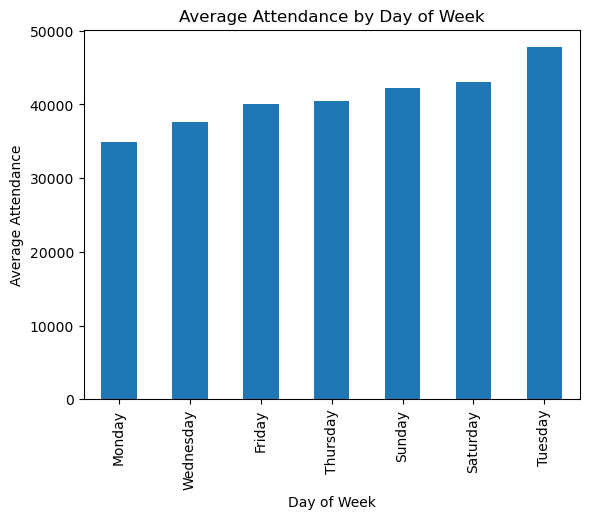

In [16]:
# Using matplotlib to create a bar chart to show Average Attendance by Day of Week
avg_by_day = ladmlb_new.groupby('day_of_week')['attend'].mean().sort_values()

avg_by_day.plot(kind='bar')
plt.title('Average Attendance by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Average Attendance')
plt.show()


__Observation of Bar Chart__<br>
Attendance is lowest on Monday, indicating weaker demand at the start of the workweek. As the week progresses, average attendance generally increases, with Wednesday, Thursday, and Friday showing moderate and relatively similar attendance levels.<br>
Notably, Tuesday records the highest average attendance, exceeding even traditional weekend days. This suggests that Tuesday games in this dataset may have benefited from favorable conditions such as popular opponents, promotions, or consistent scheduling patterns. Saturday and Sunday also demonstrate high attendance, aligning with expectations that weekend games attract larger crowds due to greater fan availability.<br>


__Insight and Recommendation__<br>
The bar chart indicates that the day of the week is strongly associated with attendance levels. <br>
While weekends perform well, certain weekdays—particularly Tuesday—can outperform weekends under the right conditions. <br>
This insight suggests that management should not only prioritize weekends but also identify and replicate the factors driving high attendance on strong-performing weekdays to improve overall attendance.

#### 3.2 Create a bar chart of Average Attendance Day vs Night Games

The bar chart illustrates the Average Attendance for day and night games.

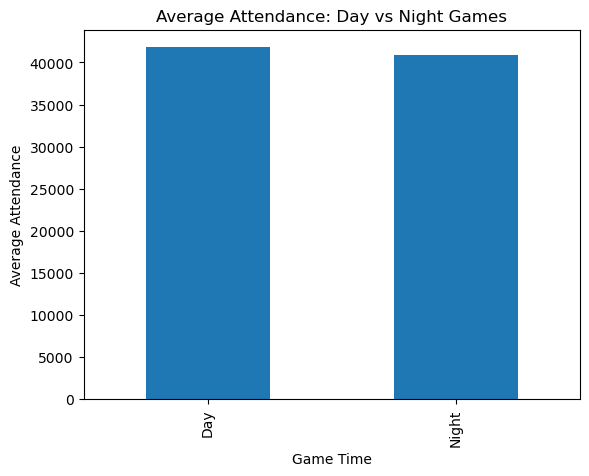

In [17]:
# Using matplotlib to create a bar chart shows Average Attendance for Day vs Night Games
day_night_avg = ladmlb_new.groupby('day_night')['attend'].mean()

day_night_avg.plot(kind='bar')
plt.title('Average Attendance: Day vs Night Games')
plt.xlabel('Game Time')
plt.ylabel('Average Attendance')
plt.show()


__Observation of Average Attendance for Day vs Night Games__<br>
The chart indicates that day games have a slightly higher average attendance than night games. However, the difference between the two is relatively modest. This suggests that both game times attract comparable crowd sizes, with a slight advantage for daytime games in this dataset.

__Insight and Recommendation__<br>
Both game times attract comparable crowd sizes, with a slight advantage for daytime games in this dataset.
This suggests that game time alone is not a dominant driver of attendance, but it does contribute marginally. From a management perspective, this implies that optimizing attendance should focus more heavily on complementary factors—such as promotions, opponent quality, and day of the week—while using game time strategically to support those initiatives rather than relying on it as a primary lever.


#### 3.3 Create a scatter chart of Attendance vs Temperature

The scatter plot illustrates the relationship between game-day temperature and attendance.

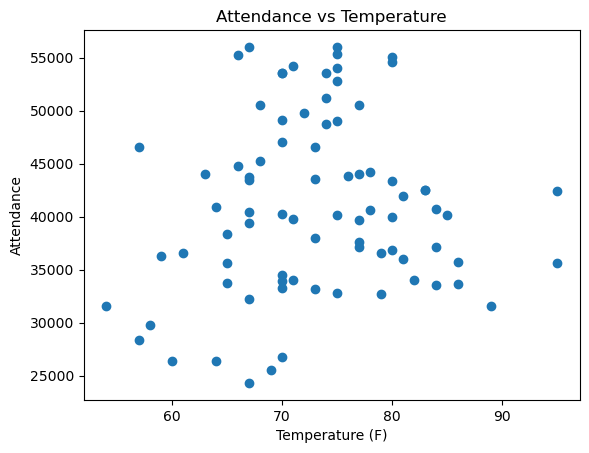

In [18]:
# Using matplotlib to create a scatter chart shows the Attendance vs Temperature

plt.scatter(ladmlb_new['temp'], ladmlb_new['attend'])
plt.xlabel('Temperature (F)')
plt.ylabel('Attendance')
plt.title('Attendance vs Temperature')
plt.show()


__Observation of Attendance vs Temperature__<br>
There is no strong linear relationship between temperature and attendance; however, several meaningful patterns emerge.<br>
Attendance appears to be highest within a moderate temperature range, roughly between 65°F and 80°F. Many of the highest attendance observations cluster in this range.<br>
In contrast, attendance tends to be lower and more variable at cooler temperatures (below 60°F) and at hotter temperatures (above 85°F), where fewer high-attendance games are observed.<br>

__Insight and Recommendation__<br>
Moderate temperatures are associated with higher attendance, while extreme heat or cold may reduce turnout.<br>
The spread of points indicates that temperature alone does not determine attendance. Games played under similar weather conditions can have substantially different attendance levels, suggesting that other factors—such as promotions, day of the week, opponent popularity, and game timing—also play a significant role alongside weather.<br>
For games forecasted to occur under less favorable temperatures, management could consider additional promotions, dynamic pricing, or enhanced fan experiences to help sustain attendance levels.<br>


#### 3.4 Create a bar chart of average attendance and promotions

Bar chart of Average Attendance With vs Without Promotions, colored by promotion types. <br>
This bar chart compares average game attendance when specific promotions are not offered (0) versus when they are offered (1).

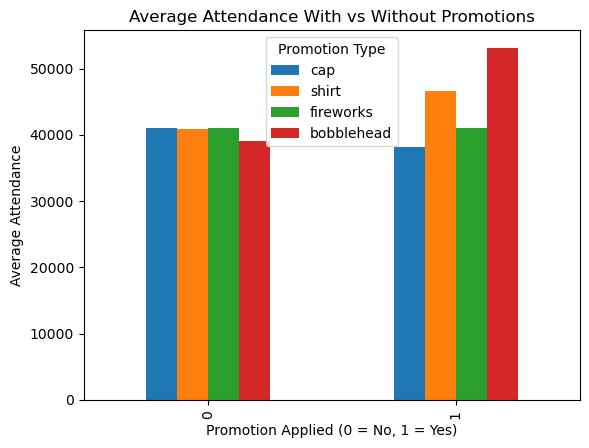

In [19]:
# Using matplotlib to create a bar chart to show the average attendance and the effect of promotions

promo_cols = ['cap', 'shirt', 'fireworks', 'bobblehead']

promo_attendance = {
    promo: ladmlb_new.groupby(promo)['attend'].mean()
    for promo in promo_cols
}

promo_df = pd.DataFrame(promo_attendance)
promo_df.plot(kind='bar')
plt.title('Average Attendance With vs Without Promotions')
plt.xlabel('Promotion Applied (0 = No, 1 = Yes)')
plt.ylabel('Average Attendance')
plt.legend(title='Promotion Type')
plt.show()


__Observation of Average Attendance & Promotions__<br>
1. Bobblehead promotions show the most substantial effect. Games featuring bobblehead giveaways have substantially higher average attendance than games without them, suggesting that this promotion is particularly effective at attracting fans.
2. Shirt promotions also demonstrate a noticeable increase in attendance when offered, indicating strong fan interest in wearable giveaways.
3. Fireworks promotions show a moderate positive effect, with attendance slightly higher when fireworks are included.
4. Cap promotions exhibit little to no difference between promoted and non-promoted games, implying that caps may be less compelling as a standalone incentive.

__Insight and Recommendation__<br>
The results indicate that promotional activities are positively associated with higher attendance. However, the magnitude of the impact varies depending on the type of promotion.
However, not all promotions deliver equal returns. To maximize attendance, resources should be prioritized toward high-impact promotions such as bobbleheads and shirt giveaways. 
Lower-impact promotions, such as caps, may be more effectively used in combination with other incentives or targeted at games that already have a strong baseline demand.


### 4. Create any additional visualizations that will help to answer the question(s)

Bar chart of the top ten opposing teams ranked by average game attendance.

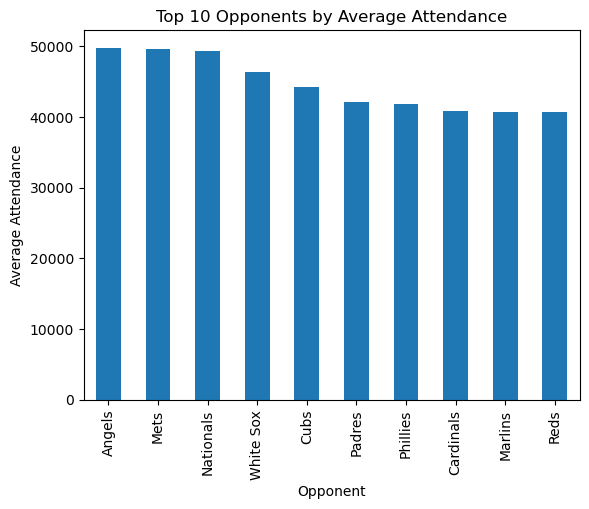

In [20]:
# Using matplotlib to create a bar chart to show the top 10 opponents by average attendance
top_opponents = (
    ladmlb_new.groupby('opponent')['attend']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)

top_opponents.plot(kind='bar')
plt.title('Top 10 Opponents by Average Attendance')
plt.xlabel('Opponent')
plt.ylabel('Average Attendance')
plt.show()


__Observation of Opponents by Average Attendance__<br>
1. Games against the Angels, Mets, and Nationals consistently generate the highest average attendance, with numbers approaching or exceeding 50,000 attendees.
2. Teams like the Padres, Phillies, Cardinals, Marlins, and Reds still draw solid attendance but with more moderate averages.
3. The results indicate that opponent identity is a meaningful factor influencing attendance, with apparent differences in average turnout depending on the visiting team.

__Insight and Recommendation__<br>
The top three teams with the highest average attendance may attract larger crowds due to factors such as geographic rivalries, strong fan bases, star players, or heightened media attention. Matchups against these opponents appear to be high-demand events. The gradual decline across the ranking suggests that while all top ten opponents perform reasonably well, some teams consistently generate more fan interest than others.<br>
This chart highlights the importance of strategic scheduling and promotion planning. High-demand opponents can be used to anchor premium pricing or marquee promotional events. In contrast, lower-demand opponents may benefit from enhanced promotions, discounted tickets, or bundled offers to boost attendance. <br>
Overall, the analysis confirms that opponent quality and appeal are key drivers of attendance and should be taken into account in attendance optimization strategies.

### 5. Storytelling & Conclusion

__Introduction of Analysis__

The objective of this analysis was to identify the key factors influencing Major League Baseball game attendance and to provide data-driven recommendations on how management can increase attendance. <br>
Using the cleaned dataset 'ladmlb_new', which contains 81 home games and a combination of scheduling, environmental, opponent, and promotional variables, the analysis followed a structured, step-by-step approach.

__Data Preparation and Validation__

The analysis began with a data quality review to ensure the reliability of the data. The dataset was confirmed to have no missing values, and duplicate records were removed. Categorical variables related to promotions were then converted into binary indicators. This ensured that the data was consistent, interpretable, and suitable for both visualization and further modeling.

__Exploratory Data Analysis__

A statistical approach using data visualization and methods to understand and summarize the main characteristics of the dataset.<br>

1. Scheduling Factors
Attendance varies by day of the week, with weekends and certain weekdays—particularly Tuesday—showing higher average turnout. Day games attract slightly more fans than night games, although the difference is small. Overall, scheduling influences attendance but is not the primary driver on its own.

2. Weather Effects
Attendance is highest during moderate temperatures (approximately 65°F–80°F). Extreme heat or cooler conditions are associated with lower and more variable attendance, indicating that weather affects turnout but interacts with other factors.

3. Promotional Impact
Promotions have varying levels of effectiveness. Bobblehead giveaways have the strongest positive association with attendance, followed by shirt promotions. Fireworks provide a moderate boost, while cap promotions show minimal impact. This highlights the importance of prioritizing high-value promotions.

4. Opponent Influence
Attendance differs significantly by opponent, with teams such as the Angels, Mets, and Nationals consistently drawing larger crowds. This confirms that opponent appeal plays a significant role in attendance and should be considered in scheduling and promotional decisions.

__Conclusion and Recommendations__

Taken together, the analysis demonstrates that attendance is driven by a combination of scheduling, promotions, opponent appeal, and environmental conditions, rather than any single factor. <br>

The strongest opportunities for management to increase attendance include:<br>

* Expanding high-impact promotions, especially bobblehead and shirt giveaways

* Using promotions strategically to boost lower-performing weekday games

* Aligning premium opponents with high-demand days and time slots

* Adjusting promotional intensity based on weather conditions

By leveraging these insights, management can adopt a more targeted and data-driven approach to attendance optimization, improving fan engagement while maximizing revenue potential.